# Milestone 03: Baseline models for abnormal next-week food price movements (H3)
**Who Pays More, and Who Can Least Afford It?** CS/SDP 312/314 Data Science for Social Good, Habib University, Fall 2026.
Group 30: Yousuf Uyghur, Sameer Hassan.

**Question (H3, SDG 2.c early warning).** Using only what is known at week *t*, can we tell which city-item prices
will move abnormally between week *t* and week *t+1*?
H0: a classifier achieves ROC-AUC = 0.5 on a time-ordered test set. H1: AUC > 0.5.

This notebook runs offline from `data/processed/m02/master_city_item_week.parquet`. All functions live in
`pfp/model.py`; `scripts/m03_models.py` runs the same steps. Every number quoted in the manuscript is written to
`reports/m03/m03_numbers.json`.

Layout, following the Milestone 03 brief:
* **Part 0.** Data, label and features.
* **Part A.** Baseline models and why we chose them.
* **Part B.** Experimental setup: time-ordered split, forward-chaining cross-validation, tuning, leakage checks.
* **Part C.** Metrics, asymmetric error costs, confusion matrices and error analysis.
* **Part D.** Feature importance, policy takeaways and the Milestone 04 roadmap.

Everything here uses methods taught in the course: logistic regression, decision trees, KNN, the confusion-matrix
metrics, ROC/PR curves, the bootstrap and permutation logic. Nothing beyond the course is used.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
from pfp import model
from pfp.config import TRAIN_CUTOFF
print("Training cutoff:", TRAIN_CUTOFF, "| random seed:", model.SEED)

Training cutoff: 2026-09-24 | random seed: 42


## Part 0. Data, label and features

### 0.1 Load the master dataset and keep the holdout closed
The master dataset from Milestone 02 holds only weeks up to the training cutoff (24 Sep 2026). The newer weeks in
`data/raw/pbs_holdout/` are reserved for the Week 14 new-data milestone. `load_master` asserts that no week after the
cutoff is present, and nothing in this notebook opens the holdout folder.

In [2]:
master = model.load_master()
assert master.week_end.max() <= pd.Timestamp(TRAIN_CUTOFF)
print(master.shape, "| weeks:", master.week_end.nunique(), "| last week:", master.week_end.max().date())

(23409, 46) | weeks: 27 | last week: 2026-09-24


### 0.2 One row = one city × food item × week *t*
`build_features` keeps food rows with a price and adds the change from week *t* to the next week (`dlog_next`).
A row can only carry a label if the next PBS release is exactly one week later (6–8 days). PBS's published archive
has gaps, so only **15 of the 27 weeks** have a consecutive next week. That is a limit of the archive, not of the method.

In [3]:
rows = model.build_features(master)
weeks = model.labelled_weeks(rows)
print(f"candidate rows: {len(rows):,} over {len(weeks)} labelled weeks")
print("labelled weeks:", [str(w)[:10] for w in weeks])
assert rows.next_week.max() <= pd.Timestamp(TRAIN_CUTOFF)

candidate rows: 8,115 over 15 labelled weeks
labelled weeks: ['2025-07-17', '2025-07-24', '2025-10-16', '2025-10-23', '2025-10-30', '2025-11-06', '2025-11-13', '2025-11-20', '2025-12-11', '2025-12-18', '2026-03-26', '2026-04-02', '2026-06-04', '2026-08-13', '2026-08-20']


### 0.3 The label: "abnormal" next-week move
`y = 1` if |log change from *t* to *t+1*| is larger than that item's own **90th percentile of non-zero changes**.
We use non-zero changes because most weekly food price changes are exactly 0: the plain 90th percentile is 0 for 13
of the 32 food items, so "abnormal" would just mean "any change". Items with fewer than 5 non-zero changes in the
training rows get no threshold and are dropped (we report how many).

**The thresholds are fitted on training rows only** (`make_labels(rows, fit_rows)`), and re-fitted inside every
cross-validation fold. If we fitted them on all weeks, the test weeks would help decide what counts as "abnormal".

The data card below uses whole-period thresholds **for description only**; the models never see them.

In [4]:
allw, thr_all = model.make_labels(rows, rows)
print(f"labelled rows {len(allw):,}; positives {allw.y.sum()}; base rate {allw.y.mean():.4f}; "
      f"rows per week {len(allw) / len(weeks):.0f}; items with a label {allw.item_id.nunique()} of {rows.item_id.nunique()}")
print(f"share of rows with no observed change at t (has_dlog = 0): {1 - allw.has_dlog.mean():.3f}")
print(f"share of rows with no observed change at t-1 (has_lag1 = 0): {1 - allw.has_lag1.mean():.3f}")

labelled rows 7,095; positives 205; base rate 0.0289; rows per week 473; items with a label 28 of 32
share of rows with no observed change at t (has_dlog = 0): 0.400
share of rows with no observed change at t-1 (has_lag1 = 0): 0.733


### 0.4 Features: every one is known at week *t*
No feature uses week *t+1*. A missing change (because the previous week was not published) is set to 0 **and**
flagged with its own `has_` column, so the model can tell "no change" from "not observed" (the M02 rule: flag, don't
impute). We do not add one dummy per item: with about 200 positives that would overfit and swamp KNN distances.

In [5]:
feat = pd.DataFrame({"feature": model.FEATURES, "why it might matter": [model.FEATURE_WHY[f] for f in model.FEATURES]})
pd.set_option("display.max_colwidth", 120); feat

,feature,why it might matter
0,abs_dlog,size of this week's change: prices that just moved may keep moving or snap back
1,has_dlog,1 if this week's change is observed (previous week published); flag instead of guessing
2,price_changed,1 if the price changed at all this week; most weeks prices are flat
3,abs_dlog_lag1,size of last week's change: a longer momentum window
4,has_lag1,1 if last week's change is observed
5,rel_price,log price relative to the national geometric mean: a city far from the others may correct
6,within_city_range_pct,(max - min) / avg across the city's outlets: disagreement may precede a move
7,single_quote,1 if min = max (one effective quote): a data-quality flag (H4)
8,cat_perishable,perishable item (reference: storable staple); expected to be most volatile (H2)
9,cat_branded_packaged,branded / packaged item; printed prices change rarely


In [6]:
# Check: no feature column is built from next-week information.
assert not any("next" in f for f in model.FEATURES)
rows[model.FEATURES].describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
abs_dlog,1.3108e-02,0.0588,0.0000,0.9808
has_dlog,6.0000e-01,0.4899,0.0000,1.0000
price_changed,1.5514e-01,0.3621,0.0000,1.0000
abs_dlog_lag1,6.5447e-03,0.0477,0.0000,0.9808
has_lag1,2.6667e-01,0.4422,0.0000,1.0000
rel_price,-3.1740e-18,0.1277,-0.7158,0.7081
within_city_range_pct,6.5547e+00,11.1972,0.0000,152.8585
single_quote,4.9020e-01,0.4999,0.0000,1.0000
cat_perishable,3.4566e-01,0.4756,0.0000,1.0000
cat_branded_packaged,2.1996e-01,0.4142,0.0000,1.0000


## Part A. Baseline models and why we chose them

| Model | Idea | Why it fits this problem |
|---|---|---|
| **Majority class** (naive benchmark 1) | always predict "normal" | shows why accuracy misleads with rare events (Unit 10, "Limitation of Accuracy") |
| **Category base-rate rule** (naive benchmark 2) | score = abnormal rate of the item's category in training weeks | a one-line domain heuristic ("perishables move more"); any ML model must beat it to be worth using |
| **Logistic regression** | linear log-odds, z-scored inputs, `class_weight="balanced"`, tune C | gives probabilities for ROC and cost thresholds, stable with ~200 positives, coefficients become odds ratios an analyst can read |
| **Decision tree (CART)** | if-then splits by Gini or entropy, `class_weight="balanced"`, tune depth and leaf size | rules a district price committee could follow without software; captures interactions; no scaling needed |
| **KNN** | vote of the K most similar rows, min-max scaled, tune K, weighting, distance | a different idea: "similar city-item situations behave alike"; no training step |

`class_weight="balanced"` gives every positive row weight n/(2·positives) and every negative n/(2·negatives), so
both classes count equally in the loss. Without it, a model can reach 97% accuracy by never predicting "abnormal".

The scalers sit **inside** each `Pipeline`, so they are refitted on the training rows of every fold and never see
validation or test rows (Unit 11, "Handling new records with a normalized model").

In [7]:
specs = model.make_models()
for name, s in specs.items():
    print(f"{name:9s} grid size {len(s['grid']):3d} | {s['est']}")

majority  grid size   1 | DummyClassifier(strategy='most_frequent')
category  grid size   1 | CategoryRateRule()
logistic  grid size   4 | Pipeline(steps=[('scale', StandardScaler()),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=5000,
                                    random_state=42))])
tree      grid size  30 | DecisionTreeClassifier(class_weight='balanced', random_state=42)
knn       grid size  48 | Pipeline(steps=[('scale', MinMaxScaler()), ('clf', KNeighborsClassifier())])


## Part B. Experimental setup and cross-validation

### B.1 Time-ordered train/test split (and why not a random stratified split)
We train on the first 11 labelled weeks (17 Jul 2025 to 26 Mar 2026) and test on the last 4 (2 Apr, 4 Jun, 13 Aug
and 20 Aug 2026): 73/27 by weeks. The rows form a panel: the same city-item series appears every week. A random split
would train on the future to predict the past, which PBS could never do in real use.

"Stratified" in the brief is about keeping the rare positive class represented in every part. We handle that by
checking positives in every fold and in the test set, and by using `class_weight="balanced"`.

**Purge rule.** A row at week *t* gets its label from week *t+1*; if *t+1* is an evaluation week, that training row's
label is built from evaluation-period prices, so we drop it. Here the last training week (26 Mar 2026) has
*t+1* = 2 Apr 2026, the first test week, so its 541 candidate rows are purged and the final model learns from 10 weeks.

In [8]:
train_weeks, test_weeks = model.time_split(rows)
final = model.split_data(rows, train_weeks, test_weeks)
train, test = final["train"], final["eval"]
print("train weeks:", [str(w)[:10] for w in train_weeks])
print("test weeks: ", [str(w)[:10] for w in test_weeks])
print(f"purged rows: {final['n_purged']} (weeks {[str(w)[:10] for w in final['purged_weeks']]})")
print(f"items without a label (fewer than 5 non-zero training changes): {final['items_unlabelled']}")
print(f"train: {len(train):,} rows, {train.y.sum()} positives, base rate {train.y.mean():.4f}")
print(f"test:  {len(test):,} rows, {test.y.sum()} positives, base rate {test.y.mean():.4f}")
# Leakage asserts
assert train.week_end.max() < min(test_weeks) and not train.next_week.isin(test_weeks).any()
assert not set(train.week_end) & set(test_weeks)

train weeks: ['2025-07-17', '2025-07-24', '2025-10-16', '2025-10-23', '2025-10-30', '2025-11-06', '2025-11-13', '2025-11-20', '2025-12-11', '2025-12-18', '2026-03-26']
test weeks:  ['2026-04-02', '2026-06-04', '2026-08-13', '2026-08-20']
purged rows: 541 (weeks ['2026-03-26'])
items without a label (fewer than 5 non-zero training changes): 5
train: 4,560 rows, 135 positives, base rate 0.0296
test:  1,824 rows, 54 positives, base rate 0.0296


The two base rates are almost equal. The pre-test, which fitted thresholds on all weeks and did not purge, had 3.2% in
train and 2.2% in test. Fitting thresholds on training weeks only lowers some items' cut-offs, so more test rows count
as abnormal. The label is now defined only by the past, as it would be in real use.

### B.2 Forward-chaining ("expanding-window") cross-validation
Inside the 11 training weeks: fold 1 trains on labelled weeks 1–6 and validates on week 7, fold 2 trains on weeks 1–7
and validates on week 8, and so on: **5 folds**. Each fold re-fits label thresholds, scaler and model on its own
training weeks and applies the purge rule. Each validation week has only 16–26 positives, so fold-to-fold variance
will be large. We report the mean ± SD.

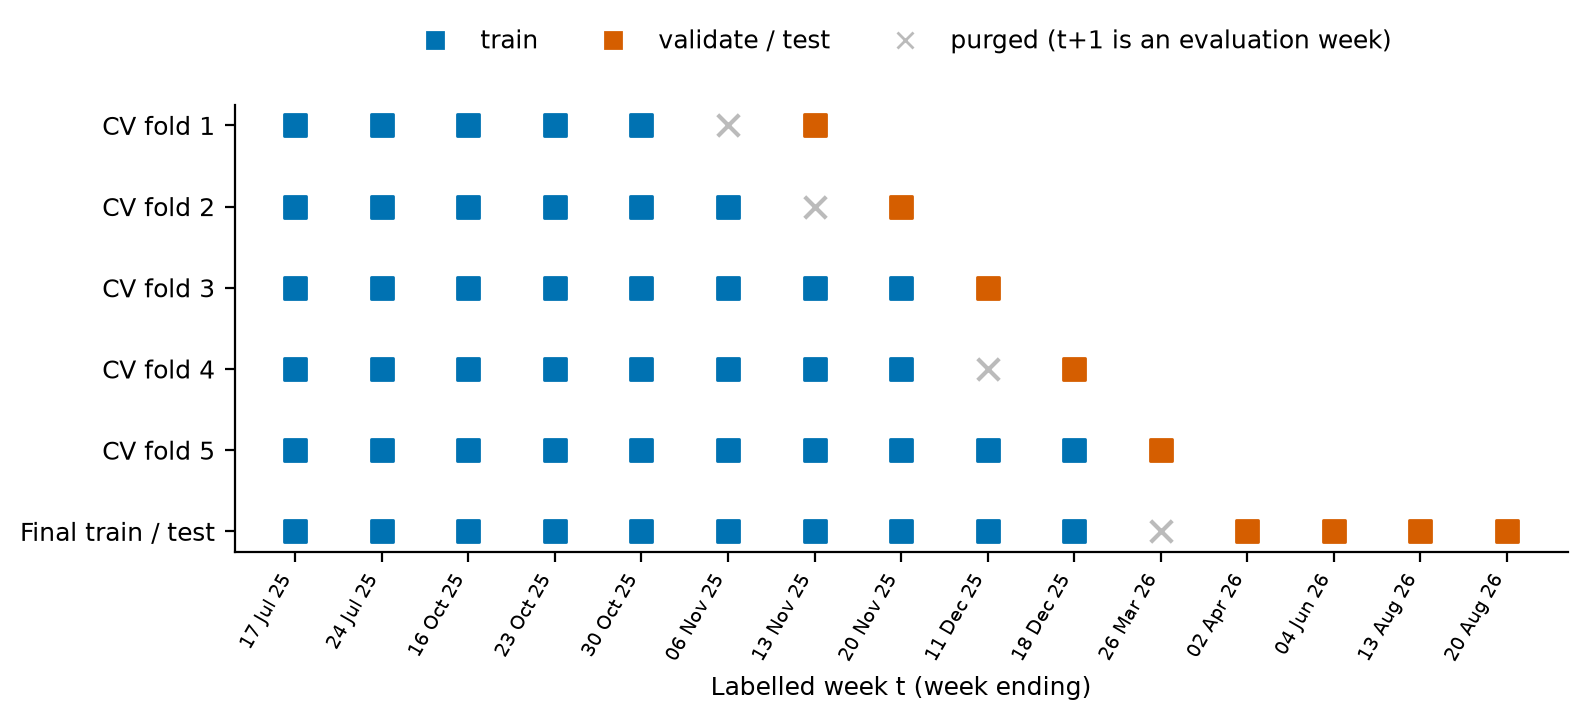

In [9]:
folds = model.forward_chain_folds(train_weeks)
fold_data = model.make_fold_data(rows, folds)
for d in fold_data:  # leakage asserts per fold
    assert d["train"].week_end.max() < min(d["eval_weeks"]) and not d["train"].next_week.isin(d["eval_weeks"]).any()
display(Image(model.fig_design(rows, train_weeks, test_weeks, folds, final["purged_weeks"])))

### B.3 Run everything
`run_all` performs the whole pipeline with exactly the folds and split shown above: tuning, CV, the single
test-set scoring, leakage checks, costs, errors and importance. It also writes all tables, figures and the numbers
JSON. It takes about two minutes. The cells after it display and explain each piece.

In [10]:
o = model.run_all(write=True)
N = model.N
o["fold_tab"]

,fold,train_weeks,n_train_weeks,val_week,purged_rows,train_rows,train_pos,val_rows,val_pos,val_rate,items_unlabelled
0,1,2025-07-17 to 2025-11-06,6,2025-11-13,541,1855,70,371,18,0.0485,10
1,2,2025-07-17 to 2025-11-13,7,2025-11-20,541,2328,87,388,16,0.0412,9
2,3,2025-07-17 to 2025-11-20,8,2025-12-11,0,3240,111,405,26,0.0642,8
3,4,2025-07-17 to 2025-12-11,9,2025-12-18,541,3240,111,405,16,0.0395,8
4,5,2025-07-17 to 2025-12-18,10,2026-03-26,0,4560,135,456,23,0.0504,5


### B.4 Hyperparameter tuning (selected by mean validation ROC-AUC)
Each grid runs inside the 5 forward-chaining folds. We use **ROC-AUC** to tune because it does not depend on a
threshold and is not fooled by the 97% majority class. If several settings are within one fold-SD of the best mean,
we take the simplest: smallest C (strongest regularisation), smallest depth with larger leaves, or largest K.

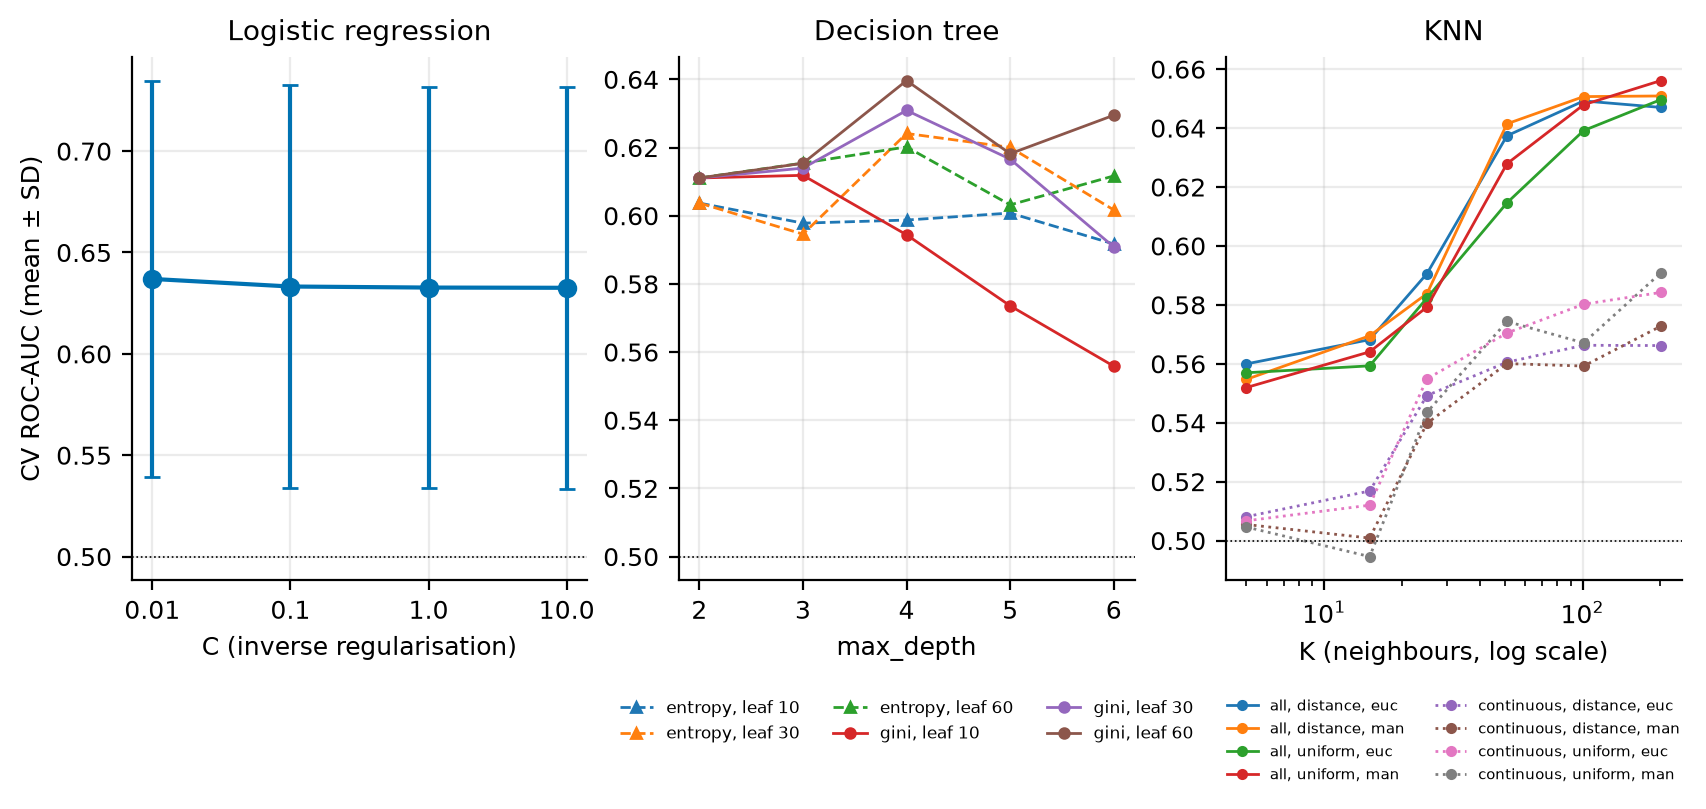

{
 "logistic": {
  "best_mean_auc": 0.637,
  "best_sd_auc": 0.0978,
  "chosen_mean_auc": 0.637,
  "chosen_sd_auc": 0.0978,
  "grid_size": 4,
  "best_params": "C=0.01",
  "chosen_params": "C=0.01"
 },
 "tree": {
  "best_mean_auc": 0.6396,
  "best_sd_auc": 0.0555,
  "chosen_mean_auc": 0.6111,
  "chosen_sd_auc": 0.0947,
  "grid_size": 30,
  "best_params": "criterion=gini, max_depth=4, min_samples_leaf=60",
  "chosen_params": "criterion=gini, max_depth=2, min_samples_leaf=60"
 },
 "knn": {
  "best_mean_auc": 0.6561,
  "best_sd_auc": 0.1329,
  "chosen_mean_auc": 0.6561,
  "chosen_sd_auc": 0.1329,
  "grid_size": 48,
  "best_params": "n_neighbors=201, weights=uniform, metric=manhattan, features=all",
  "chosen_params": "n_neighbors=201, weights=uniform, metric=manhattan, features=all",
  "best_auc_all": 0.6561,
  "best_auc_continuous": 0.5909
 }
}


In [11]:
display(Image(model.FIGURES / "fig16_tuning.png")); print(json.dumps(N["tune"], indent=1))

In [12]:
o["tuning"]["logistic"].round(3)

,clf__C,mean_auc,sd_auc,mean_pr_auc,auc_fold1,auc_fold2,auc_fold3,auc_fold4,auc_fold5,chosen,best_mean
0,0.01,0.637,0.098,0.088,0.758,0.510,0.583,0.630,0.705,True,True
1,0.10,0.633,0.100,0.085,0.756,0.503,0.581,0.624,0.703,False,False
2,1.00,0.633,0.099,0.085,0.754,0.503,0.580,0.624,0.702,False,False
3,10.00,0.633,0.099,0.085,0.754,0.503,0.580,0.624,0.702,False,False


In [13]:
o["tuning"]["tree"].sort_values("mean_auc", ascending=False).head(10).round(3)

,criterion,max_depth,min_samples_leaf,mean_auc,sd_auc,mean_pr_auc,auc_fold1,auc_fold2,auc_fold3,auc_fold4,auc_fold5,chosen,best_mean
8,gini,4,60,0.640,0.055,0.080,0.701,0.595,0.668,0.665,0.568,False,True
7,gini,4,30,0.631,0.075,0.078,0.696,0.533,0.676,0.683,0.566,False,False
14,gini,6,60,0.629,0.040,0.082,0.671,0.578,0.643,0.659,0.596,False,False
22,entropy,4,30,0.624,0.078,0.075,0.692,0.542,0.660,0.689,0.538,False,False
23,entropy,4,60,0.620,0.060,0.077,0.701,0.595,0.606,0.654,0.544,False,False
25,entropy,5,30,0.620,0.059,0.071,0.639,0.624,0.598,0.701,0.540,False,False
11,gini,5,60,0.618,0.055,0.078,0.704,0.580,0.613,0.630,0.564,False,False
10,gini,5,30,0.617,0.066,0.077,0.699,0.550,0.594,0.672,0.568,False,False
20,entropy,3,60,0.615,0.064,0.076,0.686,0.548,0.653,0.642,0.549,False,False
5,gini,3,60,0.615,0.063,0.076,0.686,0.548,0.649,0.647,0.549,False,False


In [14]:
o["tuning"]["knn"].sort_values("mean_auc", ascending=False).head(10).round(3)

,clf__n_neighbors,clf__weights,clf__metric,features,mean_auc,sd_auc,mean_pr_auc,auc_fold1,auc_fold2,auc_fold3,auc_fold4,auc_fold5,chosen,best_mean
21,201,uniform,manhattan,all,0.656,0.133,0.086,0.773,0.436,0.657,0.665,0.749,True,True
23,201,distance,manhattan,all,0.651,0.124,0.100,0.807,0.466,0.624,0.657,0.701,False,False
19,101,distance,manhattan,all,0.651,0.123,0.099,0.819,0.476,0.636,0.635,0.687,False,False
20,201,uniform,euclidean,all,0.650,0.146,0.087,0.792,0.415,0.654,0.636,0.751,False,False
18,101,distance,euclidean,all,0.649,0.113,0.099,0.798,0.486,0.630,0.640,0.692,False,False
17,101,uniform,manhattan,all,0.648,0.134,0.090,0.803,0.449,0.649,0.608,0.730,False,False
22,201,distance,euclidean,all,0.647,0.126,0.100,0.804,0.460,0.620,0.652,0.700,False,False
15,51,distance,manhattan,all,0.641,0.098,0.097,0.770,0.496,0.665,0.623,0.652,False,False
16,101,uniform,euclidean,all,0.639,0.120,0.084,0.764,0.461,0.622,0.613,0.736,False,False
14,51,distance,euclidean,all,0.637,0.102,0.093,0.757,0.476,0.659,0.629,0.665,False,False


**Reading the tuning results.**
* *Logistic regression.* C barely matters. The rule picks C = 0.01, the strongest regularisation in the grid.
* *Decision tree.* Depth 4 has the best mean, but depth 2 is within one SD, so the rule picks the simpler tree.
  A depth-2 tree is also easy to read as rules.
* *KNN.* AUC rises steadily with K and is best at K = 201, the edge of the grid. With a 3% positive rate, small
  neighbourhoods mostly contain no positives at all, so the vote is 0 for nearly everyone. Only very large
  neighbourhoods give a usable score, and then KNN is just a smoothed local base rate.
* *KNN features.* Using the continuous features only is clearly worse. The category dummies carry much of the signal.
  The Unit 11 problems all show up here: binary dummies count as much as real distances, irrelevant features add
  noise, and many rows are identical zeros, which creates ties.

### B.5 Variance across folds
Per-fold ROC-AUC for every model (chosen settings). Note how much a single fold can swing.

In [15]:
pf = o["per_fold"].pivot(index="model", columns="fold", values="roc_auc")
pf["mean"], pf["sd"] = pf.mean(axis=1), pf.std(axis=1, ddof=1)
pf.round(3)

fold,1,2,3,4,5,mean,sd
model,,,,,,,
Category base-rate rule,0.666,0.448,0.609,0.624,0.633,0.596,0.085
Decision tree,0.742,0.485,0.568,0.643,0.618,0.611,0.095
KNN,0.773,0.436,0.657,0.665,0.749,0.656,0.133
Logistic regression,0.758,0.510,0.583,0.630,0.705,0.637,0.098
Majority class,0.500,0.500,0.500,0.500,0.500,0.500,0.000


### B.6 Leakage demonstration: random K-fold is over-optimistic here
We repeat CV for the chosen logistic model with ordinary `StratifiedKFold(5, shuffle=True, random_state=42)` on the
training rows. Random folds put later weeks of the same city-item series into training and earlier weeks into
validation, so the model "knows" about periods it is validated on. The gap below is the optimism that a random
split would have reported.

In [16]:
print(f"random stratified 5-fold AUC: {N['leak']['random_kfold_auc_mean']:.3f} ± {N['leak']['random_kfold_auc_sd']:.3f}")
print(f"forward-chaining AUC:         {N['leak']['forward_auc_mean']:.3f} ± {N['cv']['logistic']['roc_auc_sd']:.3f}")
print(f"gap: {N['leak']['gap']:.3f}")

random stratified 5-fold AUC: 0.710 ± 0.038
forward-chaining AUC:         0.637 ± 0.098
gap: 0.073


### B.7 Sanity check: shuffled training labels
We refit the final logistic model on randomly permuted training labels and score the real test labels. If nothing
leaks, AUC should sit near 0.5. One shuffle is noisy with only 54 test positives, so we repeat it 200 times.
The first shuffle uses seed 42. The share of shuffled AUCs that reach the real AUC is also a permutation p-value
for H3.

In [17]:
pa = o["shuffled_aucs"]
print(f"seed-42 shuffle AUC {pa[0]:.3f}; mean over {len(pa)} shuffles {pa.mean():.3f} (SD {pa.std(ddof=1):.3f}); "
      f"5th-95th percentile {np.percentile(pa, 5):.3f}-{np.percentile(pa, 95):.3f}")
print(f"real logistic test AUC {N['test']['logistic']['roc_auc']:.3f}; share of shuffles >= real: {N['leak']['shuffled_share_ge_real']:.3f}")
assert abs(pa.mean() - 0.5) < 0.03

seed-42 shuffle AUC 0.583; mean over 200 shuffles 0.503 (SD 0.078); 5th-95th percentile 0.374-0.626
real logistic test AUC 0.692; share of shuffles >= real: 0.000


## Part C. Metrics, asymmetric costs and confusion matrices

### C.1 Main metrics: CV (mean ± SD over 5 folds) and test (scored once)
Threshold 0.5 for the threshold-based metrics. **PR-AUC** matters here because, with 3% positives, ROC-AUC can look
decent while precision stays tiny. A random model's PR-AUC equals the base rate (0.03), so compare against that, not
against 0.5. The **bootstrap 95% CI** for test ROC-AUC uses 2,000 resamples of test rows (seed 42). If its lower
bound is above 0.5, we reject H0 for that model.

In [18]:
mm = o["main"].set_index("model")
cols = []
for c in ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc"]:
    mm[f"CV {c}"] = mm[f"cv_{c}_mean"].map("{:.3f}".format) + " ± " + mm[f"cv_{c}_sd"].map("{:.3f}".format)
    cols.append(f"CV {c}")
mm["test ROC-AUC [95% CI]"] = mm.test_roc_auc.map("{:.3f}".format) + " [" + mm.test_auc_ci_lo.map("{:.3f}".format) + ", " + mm.test_auc_ci_hi.map("{:.3f}".format) + "]"
display(mm[cols])
display(mm[["test_accuracy", "test_precision", "test_recall", "test_specificity", "test_f1", "test ROC-AUC [95% CI]", "test_pr_auc", "test_flagged_at_0.5"]].round(3))

,CV accuracy,CV precision,CV recall,CV specificity,CV f1,CV roc_auc,CV pr_auc
model,,,,,,,
Majority class,0.951 ± 0.010,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.049 ± 0.010
Category base-rate rule,0.951 ± 0.010,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.596 ± 0.085,0.062 ± 0.017
Logistic regression,0.596 ± 0.065,0.072 ± 0.016,0.629 ± 0.222,0.595 ± 0.080,0.127 ± 0.029,0.637 ± 0.098,0.088 ± 0.026
Decision tree,0.678 ± 0.294,0.033 ± 0.032,0.388 ± 0.420,0.696 ± 0.334,0.061 ± 0.059,0.611 ± 0.095,0.072 ± 0.030
KNN,0.951 ± 0.010,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.656 ± 0.133,0.086 ± 0.031


,test_accuracy,test_precision,test_recall,test_specificity,test_f1,test ROC-AUC [95% CI],test_pr_auc,test_flagged_at_0.5
model,,,,,,,,
Majority class,0.970,0.000,0.000,1.000,0.000,"0.500 [0.500, 0.500]",0.030,0
Category base-rate rule,0.970,0.000,0.000,1.000,0.000,"0.708 [0.659, 0.753]",0.051,0
Logistic regression,0.570,0.050,0.759,0.564,0.095,"0.692 [0.636, 0.746]",0.052,813
Decision tree,0.868,0.035,0.130,0.890,0.055,"0.610 [0.576, 0.650]",0.038,201
KNN,0.970,0.000,0.000,1.000,0.000,"0.599 [0.529, 0.665]",0.038,0


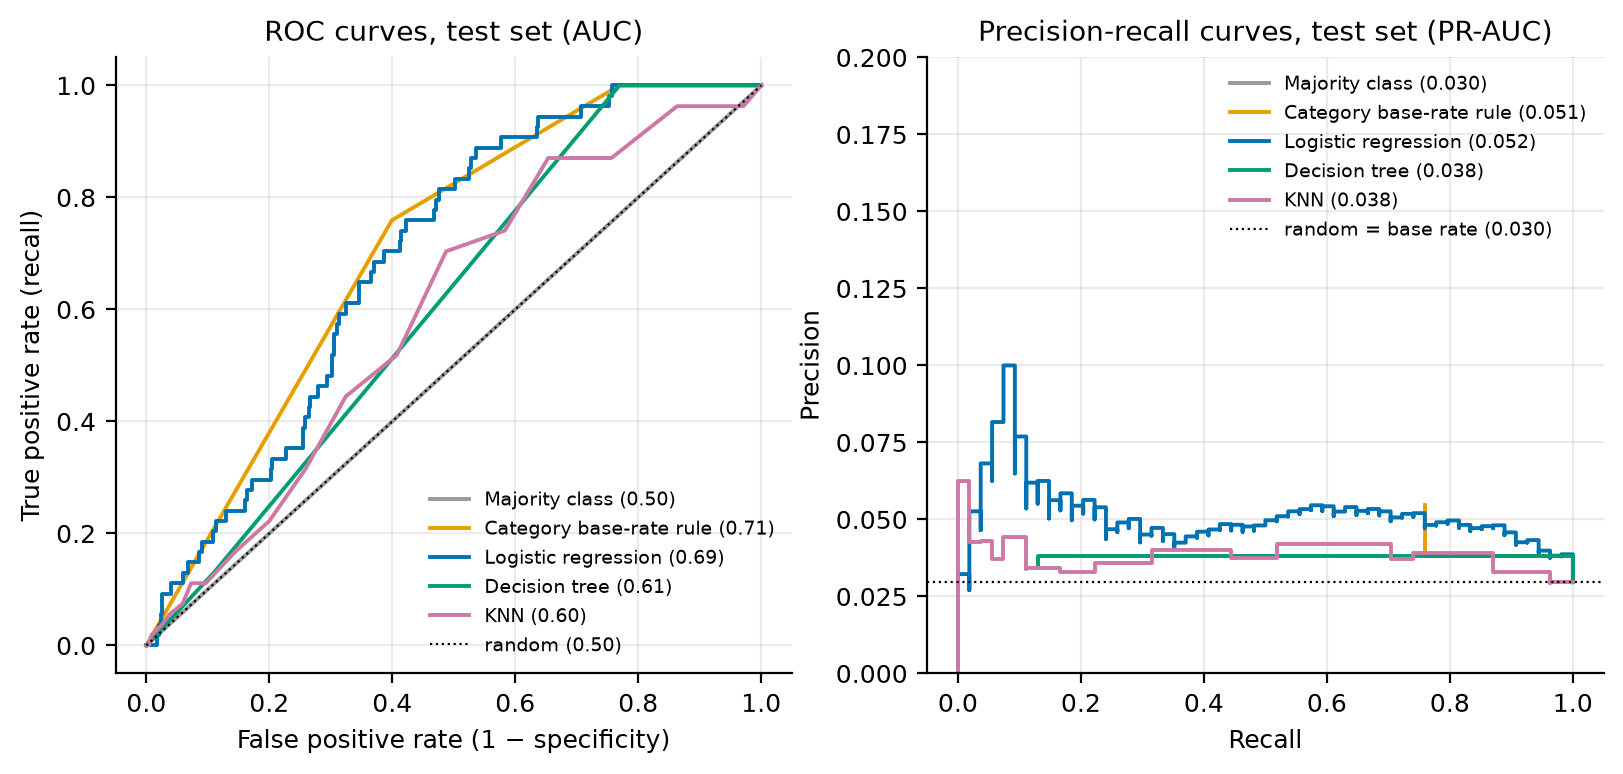

In [19]:
display(Image(model.FIGURES / "fig17_roc_pr.png"))

In [20]:
t = N["test"]
print(f"logistic minus category test AUC: {t['diff_logistic_minus_category']:.3f}, paired bootstrap 95% CI "
      f"[{t['diff_logistic_minus_category_ci_lo']:.3f}, {t['diff_logistic_minus_category_ci_hi']:.3f}]")
print("folds where logistic beats the category rule:", N["cv"]["folds_logistic_beats_category"], "of", N["cv"]["folds"])
print("H3 rejected for", N["h3"]["n_models_reject"], "of 3 ML models (CI lower bound > 0.5)")

logistic minus category test AUC: -0.015, paired bootstrap 95% CI [-0.074, 0.041]
folds where logistic beats the category rule: 4 of 5
H3 rejected for 3 of 3 ML models (CI lower bound > 0.5)


**Reading the table.**
* *Accuracy.* The majority class is about 97% accurate and catches nothing. The category rule and KNN never produce
  a score of 0.5 or more, so at that threshold they also flag nothing.
* *H3.* All three ML models have a test ROC-AUC confidence interval above 0.5, so H0 is rejected.
* *The simple rule.* The **category base-rate rule is as good as logistic regression on the test set**: their
  difference has a confidence interval spanning 0. On average across CV folds, logistic regression was ahead.
* *Practical lesson.* Most of the usable signal is "what kind of food is it". Recent price movement adds a little
  on top of that.
* *Caveat.* The bootstrap resamples rows, but rows from the same week share shocks. The CIs are therefore probably
  too narrow.

The ablation below asks directly whether recent price movements add anything beyond the item category.

In [21]:
o["ablation"].round(3)

,features,cv_auc_mean,cv_auc_sd,test_auc,test_pr_auc
0,item-category dummies only (3),0.596,0.085,0.708,0.051
1,full feature set (17),0.637,0.098,0.692,0.052


**Sensitivity to the label rule.** With the M02 "contract" rule (plain 90th percentile, where any change counts for
13 items), the base rate is higher and the task changes. We report it only as a check.

In [22]:
N["contract"]

{'test_rows': 2164,
 'test_rate': 0.0716,
 'train_rate': 0.0738,
 'logistic_test_auc': 0.5854,
 'category_test_auc': 0.5228}

### C.2 Asymmetric error costs (Provost & Fawcett, Ch. 7)
**Who uses the alert?** A PBS analyst, or a district Price Control Committee or price magistrate deciding where to
send inspectors or which items to watch next week.

* **False negative (missed abnormal move):** a jump in tomatoes, onions, flour or ghee that nobody was warned
  about. No early stock release, inspection or public notice happens. Households absorb the shock, and poorer
  households spend a larger share of income on food, so the harm falls on those least able to absorb it.
* **False positive (false alarm):** an inspection visit or watch-list entry that was not needed. It costs staff
  time and may cause friction with traders. Many false alarms lead to "alert fatigue": people stop trusting the
  system.

**Cost matrix.** We put the cost in one cell only, to avoid double counting.

| | predicted abnormal | predicted normal |
|---|---|---|
| **actual abnormal** | 0 (TP) | *r* (FN) |
| **actual normal** | 1 (FP) | 0 (TN) |

*r* is a value judgment made by people, not something the data decides, so we run a sensitivity analysis over
*r* ∈ {1, 5, 10, 20, 35}. **Intuition.** Flagging a row with probability *p* of being abnormal is worth it when
*p*·*r* > (1 − *p*), i.e. when *p* > 1/(1 + *r*). With a base rate near 3%, an average row passes that test only when
*r* is about 32 or more, roughly the inverse base rate. So around *r* ≈ 35 "flag everything" starts to look rational.

**Procedure.** For each *r*, we pick each model's threshold to minimise cost on the **pooled CV out-of-fold
predictions**, then apply that threshold to the test set once.

r,1,5,10,20,35
policy,,,,,
category,29.6,148.0,296.1,746.7,746.7
flag_everything,970.4,970.4,970.4,970.4,970.4
flag_nothing,29.6,148.0,296.1,592.1,1036.2
knn,29.6,148.0,296.1,648.6,834.4
logistic,29.6,148.0,340.5,587.7,709.4
tree,29.6,148.0,296.1,746.7,804.8


r,1,5,10,20,35
policy,,,,,
category,0.0,0.0,0.000,1.000,1.000
flag_everything,1.0,1.0,1.000,1.000,1.000
flag_nothing,0.0,0.0,0.000,0.000,0.000
knn,0.0,0.0,0.000,0.704,0.741
logistic,0.0,0.0,0.204,0.833,0.944
tree,0.0,0.0,0.000,1.000,1.000


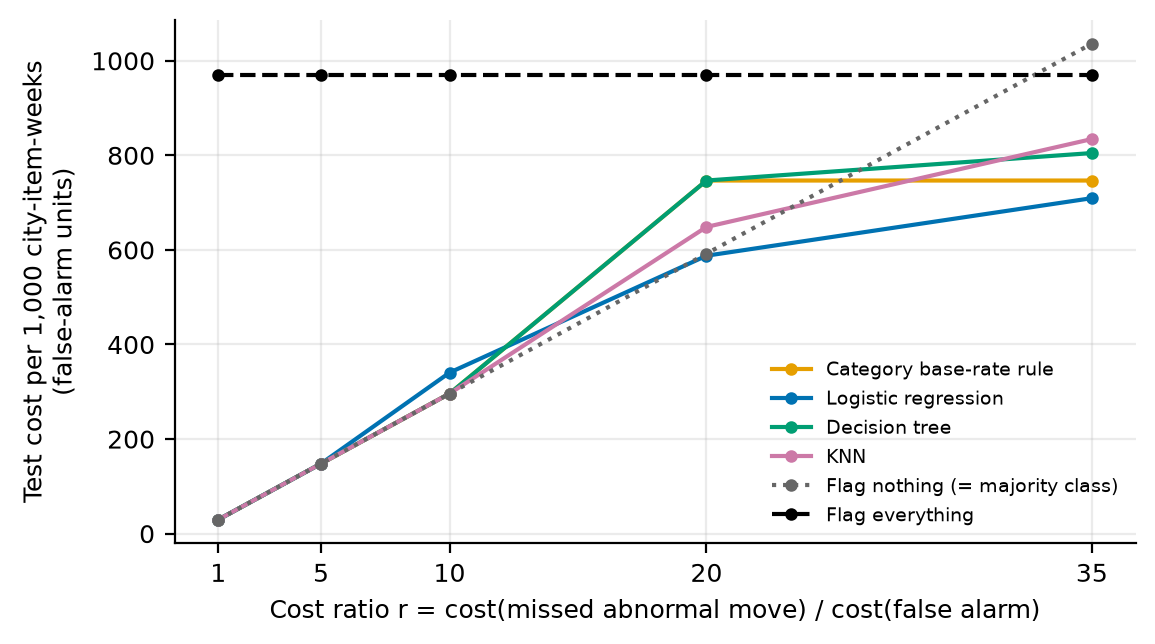

In [23]:
c = o["costs"]
display(c.pivot(index="policy", columns="r", values="test_cost_per_1000").round(1))
display(c.pivot(index="policy", columns="r", values="test_recall").round(3))
display(Image(model.FIGURES / "fig19_costs.png"))

**Reading the cost results.**
* *r ≤ 10.* The cheapest policy is to **flag nothing**: no model is confident enough. At *r* = 10 the logistic
  model's CV threshold flags a few rows, and on test that costs slightly more than flagging nothing.
* *r = 20.* Logistic regression and "flag nothing" cost about the same.
* *r = 35.* Logistic regression is the cheapest policy.

So the model only pays off if a missed shock is judged to cost roughly 20 or more false alarms. Whoever deploys it
has to make that call; we cannot.

In [24]:
print("Metrics at the cost-based threshold, r =", model.R_REF, "(threshold chosen on CV, applied to test)")
o["at_ref"].round(3)

Metrics at the cost-based threshold, r = 20 (threshold chosen on CV, applied to test)


,model,threshold,accuracy,precision,recall,specificity,f1,tp,fp,fn,tn
0,Category base-rate rule,0.025,0.253,0.038,1.000,0.231,0.073,54,1362,0,408
1,Logistic regression,0.469,0.506,0.048,0.833,0.496,0.091,45,892,9,878
2,Decision tree,0.471,0.253,0.038,1.000,0.231,0.073,54,1362,0,408
3,KNN,0.030,0.518,0.042,0.704,0.512,0.080,38,863,16,907


### C.3 Alert-budget view
An analyst can check only the top *N* of the roughly 456 city-items each week. How many real abnormal moves would
each model put in front of them? The category rule gives tied scores, so we report the expected count under random
tie-breaking.

In [25]:
o["budget"].round(3)

,model,N_per_week,caught,positives,recall_at_N,precision_at_N
0,category,10,2.193,54,0.041,0.055
1,category,25,5.481,54,0.102,0.055
2,category,50,10.963,54,0.203,0.055
3,logistic,10,2.000,54,0.037,0.050
4,logistic,25,7.000,54,0.130,0.070
5,logistic,50,11.000,54,0.204,0.055
6,tree,10,1.399,54,0.026,0.035
7,tree,25,3.498,54,0.065,0.035
8,tree,50,6.995,54,0.130,0.035
9,knn,10,1.921,54,0.036,0.048


### C.4 Equity weighting (preview of the M04 fairness audit)
We repeat the cost analysis with the FN cost multiplied by the city's deprivation tercile weight (low 1, mid 1.5,
high 2): a missed shock in a more deprived city counts more.

In [26]:
ce = o["costs_eq"]; display(ce.pivot(index="policy", columns="r", values="test_cost_per_1000").round(1)); N["cost_equity"]

r,1,5,10,20,35
policy,,,,,
category,45.5,227.5,505.5,746.7,746.7
flag_everything,970.4,970.4,970.4,970.4,970.4
flag_nothing,45.5,227.5,455.0,910.1,1592.7
knn,45.5,227.5,552.6,801.5,978.3
logistic,45.5,278.8,503.8,706.7,781.8
tree,45.5,227.5,501.1,804.8,804.8


{'r10': {'cheapest': 'flag_nothing',
  'logistic_threshold': 0.5883,
  'logistic_recall': 0.463,
  'logistic_cost': 503.8377},
 'r20': {'cheapest': 'logistic',
  'logistic_threshold': 0.3545,
  'logistic_recall': 0.9444,
  'logistic_cost': 706.6886},
 'r35': {'cheapest': 'category',
  'logistic_threshold': 0.3296,
  'logistic_recall': 0.9444,
  'logistic_cost': 781.7982}}

### C.5 Confusion matrices (Unit 10 layout: actual in rows, predicted in columns, positive class first)

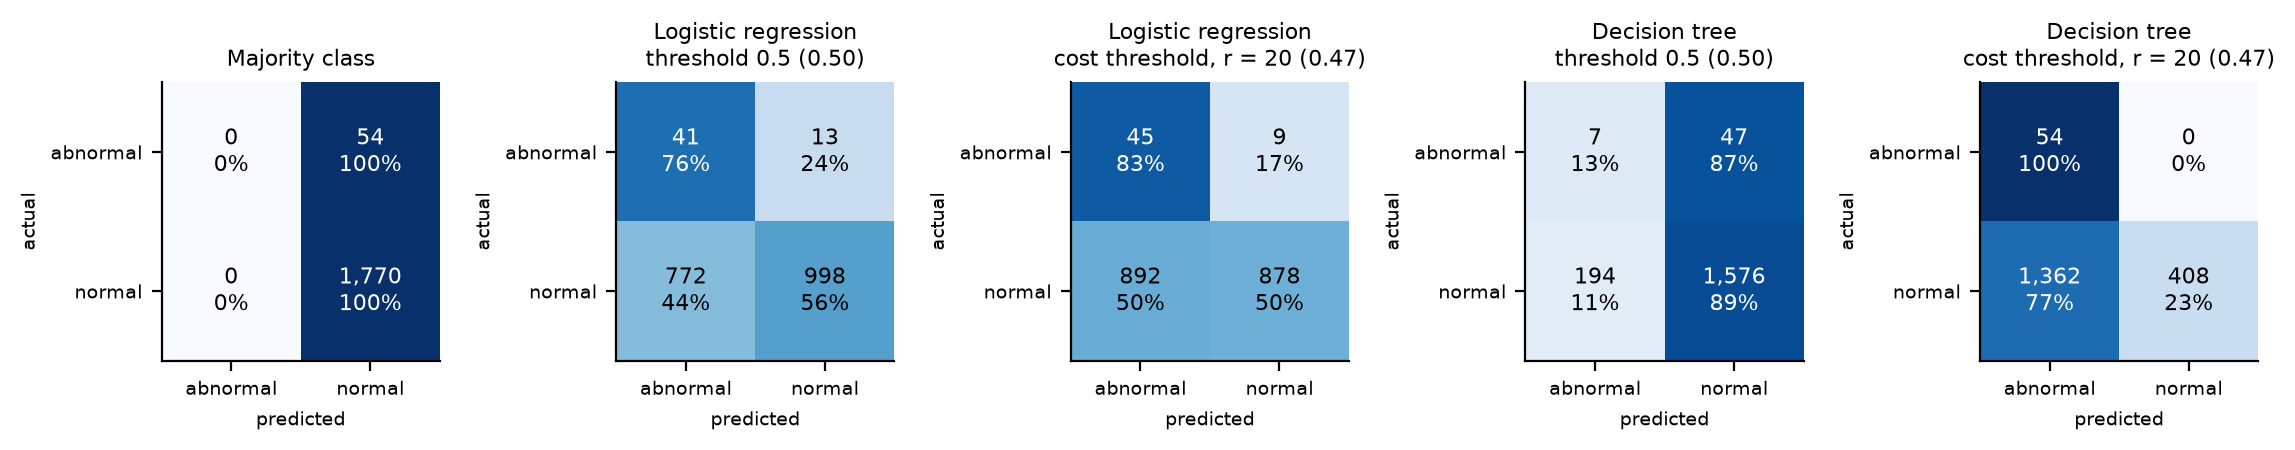

,matrix,TP,FN,FP,TN,recall (TP row %),specificity (TN row %)
0,Majority class,0,54,0,1770,0.000,1.000
1,"Logistic regression, threshold 0.5 (0.50)",41,13,772,998,0.759,0.564
2,"Logistic regression, cost threshold, r = 20 (0.47)",45,9,892,878,0.833,0.496
3,"Decision tree, threshold 0.5 (0.50)",7,47,194,1576,0.130,0.890
4,"Decision tree, cost threshold, r = 20 (0.47)",54,0,1362,408,1.000,0.231
5,"KNN, threshold 0.5 (0.50)",0,54,0,1770,0.000,1.000
6,"KNN, cost threshold, r = 20 (0.03)",38,16,863,907,0.704,0.512


In [27]:
display(Image(model.FIGURES / "fig18_confusion.png")); o["cm_tab"].round(3)

### C.6 Where the errors fall (logistic regression, cost threshold *r* = 20), descriptive only
FN rate = missed share of real abnormal moves; FP rate = false-alarm share of normal rows. The formal fairness test
is Milestone 04. Group sizes are small (a few positives per province), so read these as patterns, not findings.

In [28]:
o["errors"].round(3)

,grouping,group,rows,positives,base_rate,flagged,fn_rate,fp_rate
0,item category,branded_packaged,408,0,0.000,0,NaN,0.000
1,item category,perishable,748,41,0.055,629,0.122,0.839
2,item category,storable_staple,668,13,0.019,308,0.308,0.456
3,province,Balochistan,216,5,0.023,109,0.400,0.502
4,province,ICT,108,2,0.019,3,1.000,0.028
5,province,KP,216,9,0.042,127,0.333,0.585
6,province,Punjab,852,28,0.033,418,0.071,0.476
7,province,Sindh,432,10,0.023,280,0.000,0.640
8,city-size tercile,large,640,18,0.028,271,0.056,0.408
9,city-size tercile,medium,540,20,0.037,284,0.300,0.519


### C.7 Edge cases: the most confident mistakes
Ten most confident false negatives (lowest score among missed abnormal moves) and ten most confident false positives.

In [29]:
display(o["fn_cases"].round(3)); display(o["fp_cases"].round(3))

,city,item_short,item_category,week,score,dlog_next,threshold,abs_dlog,has_dlog,price_changed,abs_dlog_lag1,rel_price,within_city_range_pct,single_quote
0,Quetta,Rice basmati broken,storable_staple,2026-08-20,0.272,-0.072,0.045,0.0,1,0.0,0.0,0.286,6.898,0.0
1,Quetta,Rice IRRI-6/9,storable_staple,2026-08-20,0.278,-0.061,0.058,0.0,1,0.0,0.0,0.094,11.773,0.0
2,Multan,Garlic,perishable,2026-04-02,0.328,-0.219,0.149,0.0,1,0.0,0.0,-0.079,85.164,0.0
3,Islamabad,Eggs (farm),perishable,2026-06-04,0.377,-0.148,0.057,0.0,0,0.0,0.0,0.026,4.110,0.0
4,Islamabad,Eggs (farm),perishable,2026-08-13,0.378,-0.096,0.057,0.0,0,0.0,0.0,0.026,3.681,0.0
5,Bahawalpur,Pulse gram,storable_staple,2026-08-20,0.412,0.159,0.069,0.0,1,0.0,0.0,-0.223,9.384,0.0
6,Peshawar,Bananas,perishable,2026-04-02,0.447,-0.116,0.110,0.0,1,0.0,0.0,0.174,12.346,0.0
7,Peshawar,Mutton,perishable,2026-04-02,0.456,0.062,0.035,0.0,1,0.0,0.0,-0.064,18.719,0.0
8,Peshawar,Wheat flour 20kg,storable_staple,2026-06-04,0.458,-0.040,0.039,0.0,0,0.0,0.0,0.113,3.674,0.0


,city,item_short,item_category,week,score,dlog_next,threshold,abs_dlog,has_dlog,price_changed,abs_dlog_lag1,rel_price,within_city_range_pct,single_quote
0,Larkana,Onions,perishable,2026-08-20,0.854,-0.161,0.416,0.379,1,1.0,0.0,0.048,0.000,1.0
1,Sukkur,Tomatoes,perishable,2026-04-02,0.844,0.000,0.624,0.061,1,1.0,0.0,-0.476,0.000,1.0
2,Sukkur,Potatoes,perishable,2026-04-02,0.843,0.000,0.187,0.182,1,1.0,0.0,-0.260,0.000,1.0
3,Sukkur,Tomatoes,perishable,2026-08-20,0.841,-0.288,0.624,0.223,1,1.0,0.0,-0.166,0.000,1.0
4,Bannu,Eggs (farm),perishable,2026-08-20,0.837,0.000,0.057,0.077,1,1.0,0.0,0.002,0.000,1.0
5,Sukkur,Onions,perishable,2026-04-02,0.837,0.000,0.416,0.122,1,1.0,0.0,-0.250,0.000,1.0
6,Bannu,Eggs (farm),perishable,2026-04-02,0.835,0.000,0.057,0.043,1,1.0,0.0,-0.017,0.000,1.0
7,Larkana,Garlic,perishable,2026-08-20,0.835,-0.044,0.149,0.090,1,1.0,0.0,-0.215,6.525,0.0
8,Bannu,Chicken broiler (live),perishable,2026-04-02,0.833,0.022,0.169,0.034,1,1.0,0.0,0.012,0.000,1.0
9,Bannu,Tomatoes,perishable,2026-04-02,0.830,0.145,0.624,0.212,1,1.0,0.0,0.072,11.557,0.0


In [30]:
{k: v for k, v in N["errors"].items() if k.startswith(("fn_", "tp_", "n_", "positives"))}

{'n_fn': 9,
 'n_tp': 45,
 'fn_share_price_changed': 0.0,
 'tp_share_price_changed': 0.2444,
 'fn_share_has_dlog': 0.6667,
 'tp_share_has_dlog': 0.4667,
 'fn_share_single_quote': 0.0,
 'tp_share_single_quote': 0.4889,
 'fn_share_cat_perishable': 0.5556,
 'tp_share_cat_perishable': 0.8,
 'fn_share_flat_or_unobserved': 1.0,
 'positives_flat_or_unobserved_rate': 0.0274,
 'positives_changed_rate': 0.043}

**Patterns.**
* *Missed moves (FN).* Every missed abnormal move at this threshold had a flat or unobserved price at week *t*
  (`price_changed = 0`). Nothing in the recent history pointed to a move. Moves that come "out of the blue" are
  invisible to a model built on recent changes.
* *False alarms (FP).* The most confident false alarms are perishables in Sukkur, Bannu and Larkana, mostly
  records with one effective quote (`single_quote = 1`) whose price changed this week and then stayed put. A single
  quote that jumps may be noise in one shop rather than a market move. That links to the H4 data-quality concern.
* *Event timing (unverified).* The two earlier test weeks (2 Apr and 4 Jun 2026) have about twice the base rate of
  the two August weeks. Each falls within about two weeks of an Eid holiday: Eid al-Fitr is expected around
  20 March 2026 and Eid al-Adha around 27 May 2026. Post-festival price adjustment is **one possible explanation,
  which we have not tested**.

## Part D. Feature importance and initial insights

### D.1 Logistic regression: standardised coefficients and odds ratios per 1 SD
Inputs are z-scored inside the pipeline, so each coefficient is the change in log-odds for a one-standard-deviation
increase. The odds ratio = e^coef. These are associations, not causes.

,feature,coef_per_sd,odds_ratio_per_sd,tree_importance,rank_logistic,rank_tree
0,cat_branded_packaged,-0.513,0.599,0.584,1,1.0
1,price_changed,0.384,1.467,0.000,2,NaN
2,cat_perishable,0.284,1.328,0.000,3,NaN
3,has_dlog,-0.234,0.791,0.000,4,NaN
4,prov_ICT,-0.221,0.802,0.000,5,NaN
5,has_lag1,-0.186,0.831,0.000,6,NaN
6,log_pop_urban,-0.181,0.834,0.000,7,NaN
7,deprivation_composite,0.138,1.148,0.000,8,NaN
8,prov_Balochistan,-0.120,0.887,0.000,9,NaN
9,within_city_range_pct,-0.106,0.900,0.000,10,NaN


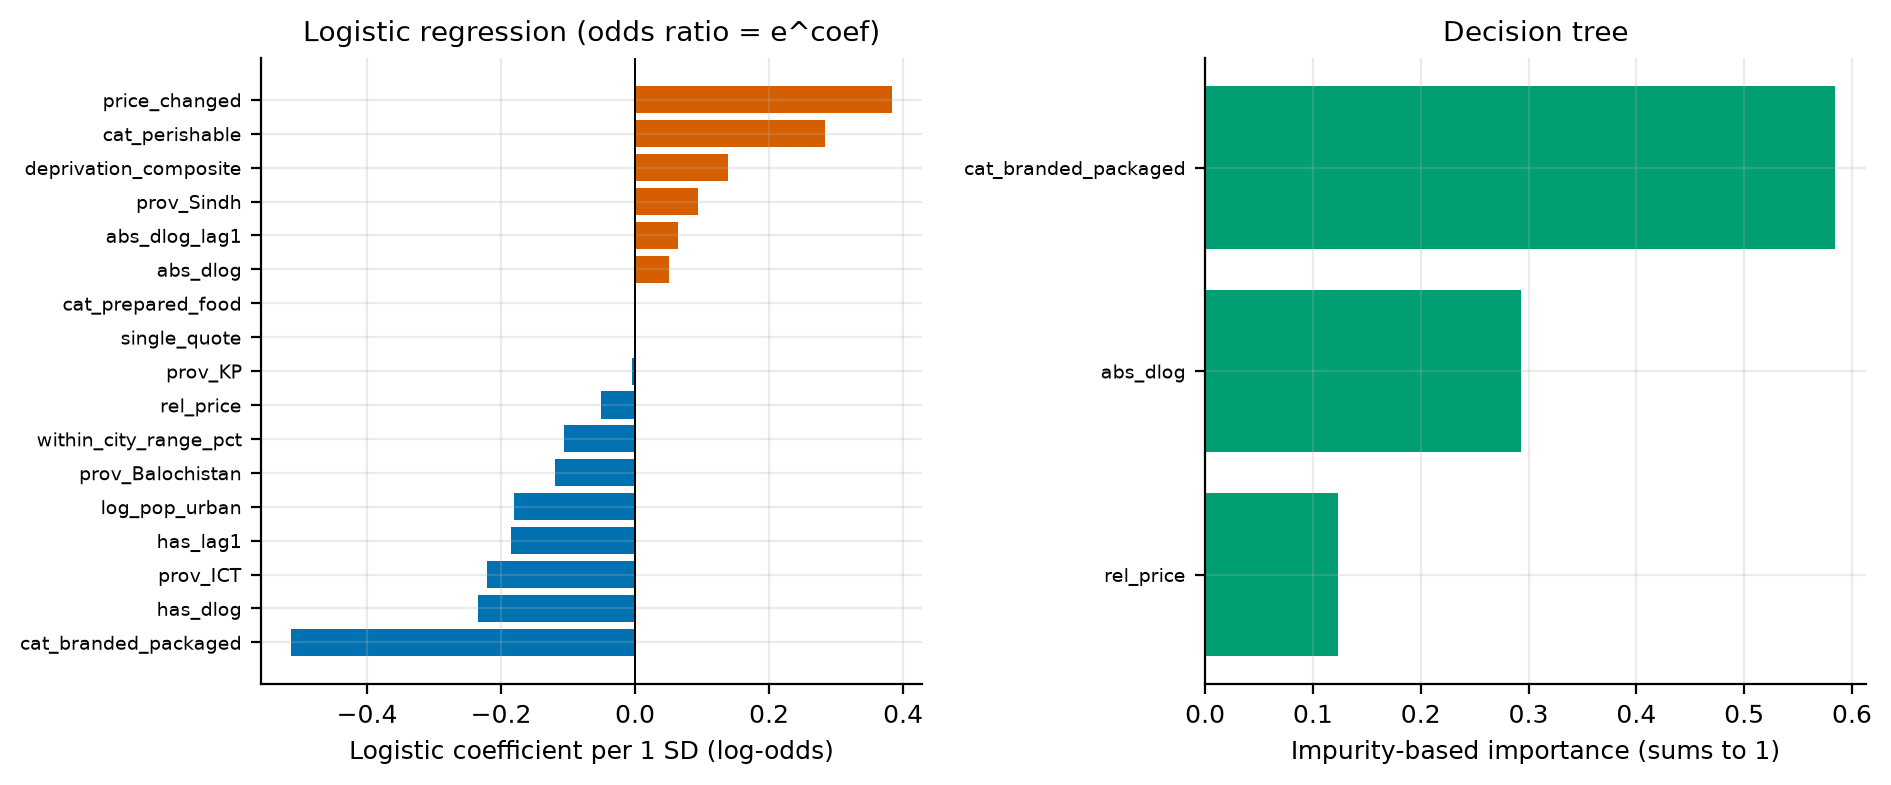

In [31]:
imp = o["importance"]; display(imp.round(3)); display(Image(model.FIGURES / "fig20_importance.png"))

In [32]:
for r in imp.head(5).itertuples():
    direction = "higher" if r.odds_ratio_per_sd > 1 else "lower"
    print(f"{r.feature}: one SD higher is associated with {r.odds_ratio_per_sd:.2f} times the odds of an abnormal move next week ({direction})")
print("correlation between abs_dlog and price_changed in training rows:", round(N["imp"]["corr_abs_dlog_price_changed"], 3))

cat_branded_packaged: one SD higher is associated with 0.60 times the odds of an abnormal move next week (lower)
price_changed: one SD higher is associated with 1.47 times the odds of an abnormal move next week (higher)
cat_perishable: one SD higher is associated with 1.33 times the odds of an abnormal move next week (higher)
has_dlog: one SD higher is associated with 0.79 times the odds of an abnormal move next week (lower)
prov_ICT: one SD higher is associated with 0.80 times the odds of an abnormal move next week (lower)
correlation between abs_dlog and price_changed in training rows: 0.5


**Reading the coefficients.**
* *Item type.* Branded and packaged goods are much less likely to move abnormally; perishables more likely.
* *Recent movement.* A price that changed this week (`price_changed`) is more likely to move abnormally next week.
  `abs_dlog` gets only a small coefficient because it is correlated with `price_changed` (r about 0.5), and the two share
  the credit (the Unit 09 point about correlated features splitting importance).
* *Market size.* Larger markets (`log_pop_urban`, Islamabad) are associated with fewer abnormal moves.
* *Observation flags.* The `has_` flags are negative. They mostly mark *which weeks* had a published previous
  week, so they partly stand in for time period. They are not a market effect.

### D.2 Decision tree: importance, rules and a worked Gini example

|--- cat_branded_packaged <= 0.50
|   |--- abs_dlog <= 0.01
|   |   |--- class: 0
|   |--- abs_dlog >  0.01
|   |   |--- class: 1
|--- cat_branded_packaged >  0.50
|   |--- rel_price <= -0.01
|   |   |--- class: 0
|   |--- rel_price >  -0.01
|   |   |--- class: 0



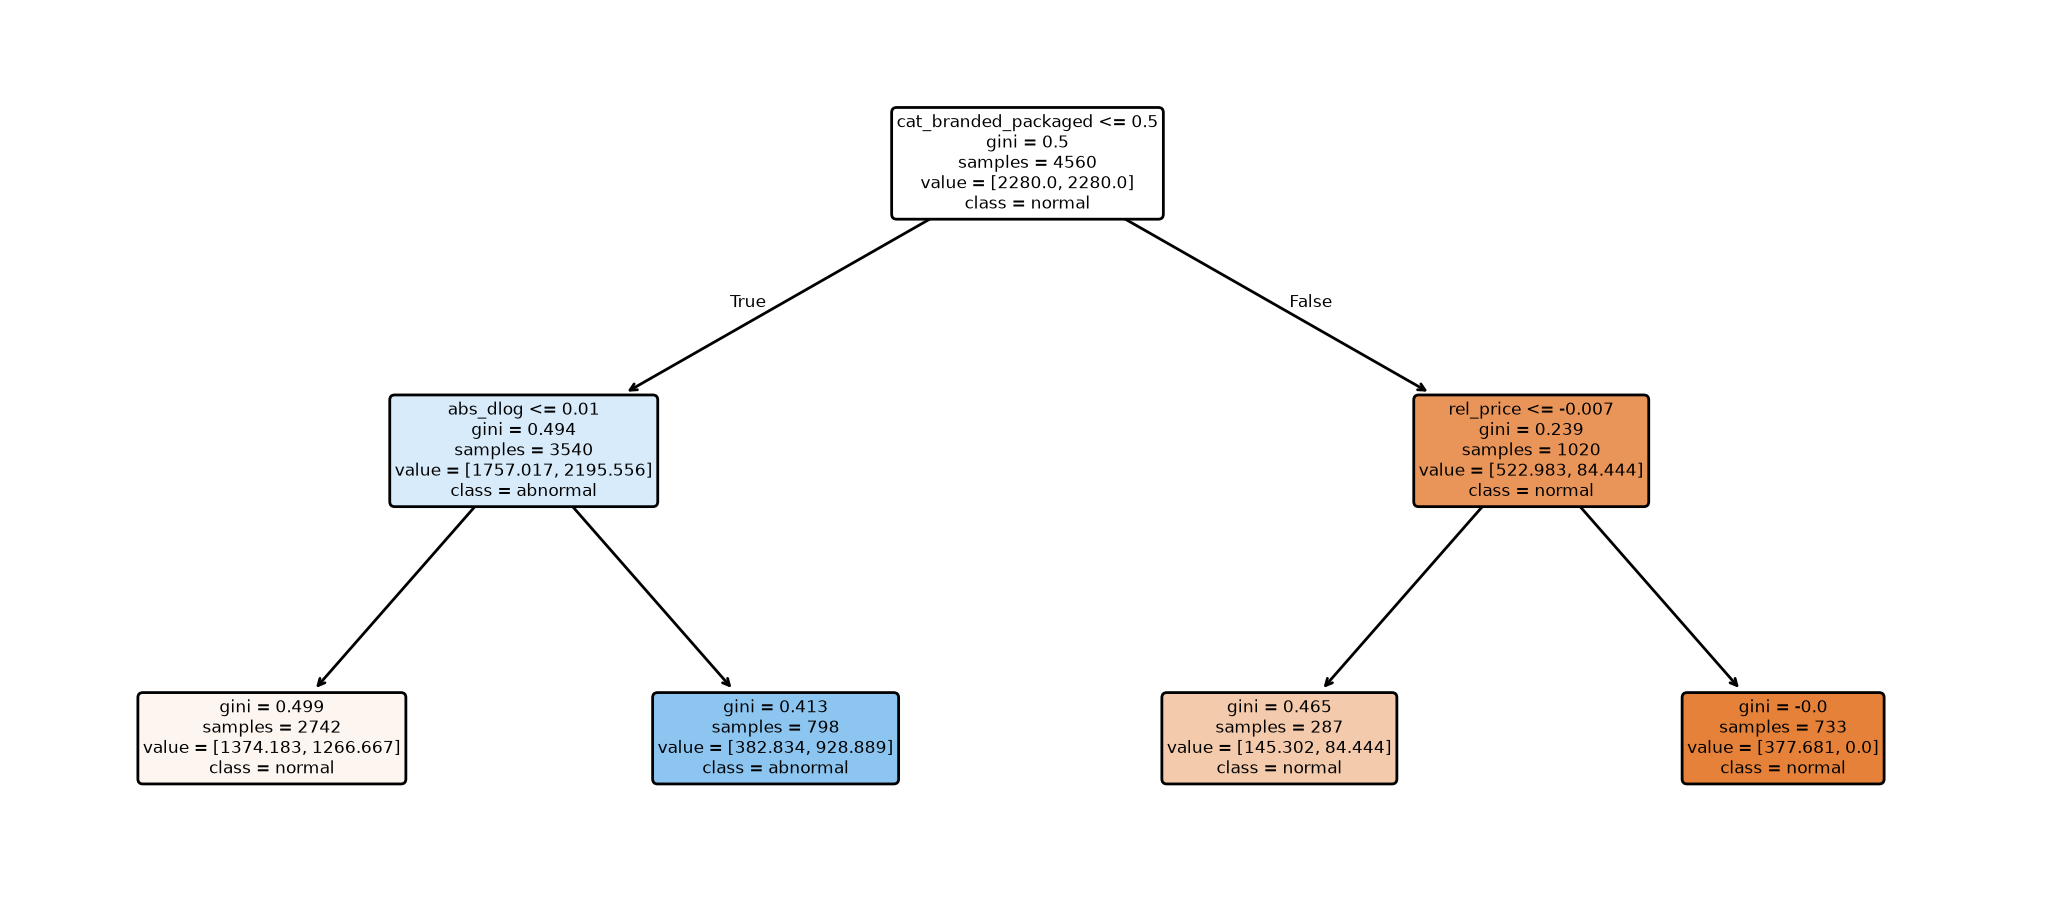

,leaf,rule,train_rows,train_positives,abnormal_rate
0,3,IF cat_branded_packaged <= 0.5 AND abs_dlog > 0.0101,798,55,0.0689
1,2,IF cat_branded_packaged <= 0.5 AND abs_dlog <= 0.0101,2742,75,0.0274
2,5,IF cat_branded_packaged > 0.5 AND rel_price <= -0.00741,287,5,0.0174
3,6,IF cat_branded_packaged > 0.5 AND rel_price > -0.00741,733,0,0.0000


In [33]:
print(o["rules_text"]); display(Image(model.FIGURES / "fig21_tree.png")); o["rules"]

The plotted `value` is the **class-weighted** count, because the tree was fitted with balanced class weights.
The rule table gives the actual (unweighted) abnormal rate of each leaf on the training rows. The top rule reads:
**IF the item is not branded/packaged AND its price moved by more than about 1% this week, THEN the chance of an
abnormal move next week is about 7%**, more than twice the base rate.

**Worked Gini example (root split).** Gini = 1 − p² − (1 − p)². The split's gain is the parent's Gini minus the
size-weighted Gini of the two children. sklearn computes this with the class weights, which make the root
exactly 50/50.

In [34]:
g = o["gini_example"]
print(f"root split: {g['feature']} <= {g['threshold']}")
print(f"unweighted counts: parent {g['pos']}/{g['n']} positive -> left {g['pos_left']}/{g['n_left']}, right {g['pos_right']}/{g['n_right']}")
print(f"unweighted Gini: parent {g['gini_parent']:.4f}, left {g['gini_left']:.4f}, right {g['gini_right']:.4f}, weighted children {g['gini_weighted_children']:.4f}, gain {g['gini_gain']:.4f}")
print(f"class weights: positive {g['w_pos']:.2f}, negative {g['w_neg']:.3f}")
print(f"weighted Gini (what sklearn used): parent {g['wgini_parent']:.4f}, left {g['wgini_left']:.4f}, right {g['wgini_right']:.4f}, "
      f"left share of weight {g['wshare_left']:.3f}, children {g['wgini_weighted_children']:.4f}, gain {g['wgini_gain']:.4f}")

root split: cat_branded_packaged <= 0.5
unweighted counts: parent 135/4560 positive -> left 130/3540, right 5/1020
unweighted Gini: parent 0.0575, left 0.0707, right 0.0098, weighted children 0.0571, gain 0.0004
class weights: positive 16.89, negative 0.515
weighted Gini (what sklearn used): parent 0.5000, left 0.4938, right 0.2394, left share of weight 0.867, children 0.4599, gain 0.0401


### D.3 Cross-model check
Features that rank high in both models are the most trustworthy drivers: the branded/packaged flag (both models) and
recent price movement (`price_changed` in the logistic model, `abs_dlog` in the tree, which are two views of the same
signal). A depth-2 tree can use only three features, so most features have no tree importance.

In [35]:
imp[["feature", "rank_logistic", "rank_tree", "odds_ratio_per_sd", "tree_importance"]].round(3)

,feature,rank_logistic,rank_tree,odds_ratio_per_sd,tree_importance
0,cat_branded_packaged,1,1.0,0.599,0.584
1,price_changed,2,NaN,1.467,0.000
2,cat_perishable,3,NaN,1.328,0.000
3,has_dlog,4,NaN,0.791,0.000
4,prov_ICT,5,NaN,0.802,0.000
5,has_lag1,6,NaN,0.831,0.000
6,log_pop_urban,7,NaN,0.834,0.000
7,deprivation_composite,8,NaN,1.148,0.000
8,prov_Balochistan,9,NaN,0.887,0.000
9,within_city_range_pct,10,NaN,0.900,0.000


### D.4 Initial policy takeaways (SDG 2.c), hedged
1. **Where to look.** Concentrate weekly monitoring on perishables, especially those whose price already moved this
   week. Branded and packaged goods almost never move abnormally.
2. **Triage aid, not a trigger.** With test AUC around 0.7 and precision around 5%, most alerts will be false.
   The model can rank where an inspector looks first; it should not trigger action automatically.
3. **A simple rule already captures most of the signal.** On the test weeks, "watch perishables" does as well as
   the logistic model. Any ML system must beat that rule to justify its cost.
4. **Publish every week.** 40% of labelled rows have no previous consecutive week, because PBS's published weekly
   archive has gaps, and the moves we miss are the ones with no visible recent history. Consistent publication of
   the weekly annexure is a cheap way to improve early warning.
5. **The threshold is a policy choice.** Whether alerts are worth issuing depends on how many false alarms one
   missed shock is worth (*r*). Below about 20, issuing no alerts is cheaper. That judgment belongs to decision-makers.

### D.5 Limitations and the Milestone 04 roadmap
**Limitations**
* Only about 200 positives over 15 labelled weeks; 4 test weeks with 54 positives, so wide confidence intervals.
* The bootstrap ignores clustering by week, so the CIs are probably too narrow.
* Gaps in the archive; class imbalance; modest signal; KNN unsuitable.
* The 90th-percentile threshold is a convention.
* City-level external variables are constant within a city. Islamabad and Rawalpindi function as one market.
* Possible place-based bias in who gets missed.

**Milestone 04**
* Tree ensembles (random forest, boosting) compared against today's baselines.
* Fairness audit (H4): recall, FN rate and calibration across province, population tercile and deprivation
  tercile, with a hypothesis test.
* Thresholds that equalise miss rates, and an ethical evaluation of who bears the false negatives.
* The Week 14 design: first score the frozen model on the post-cutoff holdout weeks, then retrain on the earlier part
  of the new data and test on a later, unseen part.

In [36]:
# Final checks before the numbers are used in the manuscript.
assert N["data"]["max_week_used"] <= str(TRAIN_CUTOFF)
assert abs(N["leak"]["shuffled_mean"] - 0.5) < 0.03
print("all checks passed; numbers file:", model.NUMBERS_JSON.relative_to(ROOT))

all checks passed; numbers file: reports\m03\m03_numbers.json
